# When the trained facts change but stay known, do the carrying neurons move? (E105)

*2026-11-06. Provisional. Independent check: holds with caveat (`reports/reviews/2026-11-06_review_e105-independent-check.md`).
Full record: `reports/analyses/2026-11-06_analysis_e105-rows-null.md`.*

## The answer

Swapping every trained fact for a different set of facts the model already knows leaves the carrying neurons nearly
where they were. Two halves of the real facts share about five sixths of their carrying neurons, close to what two
seeds share and far above the half a known-facts run shared with a fictional-facts run. The filed rule reads "label" on
both row sets, against both filed leans. So the earlier separation survives a change of rows and seed. It is not yet a
reading of known against new: answer style and topic still differ between the two kinds of training.


## What we were trying to test

`GOALS.md` asks whether post-training strengthens what a model already does or teaches it something new. E103 trained
Qwen3-1.7B on TOFU's 217 real-world facts, which it already knows, and compared that with a run on TOFU's invented
authors, which it cannot know. One neuron reading told them apart beyond seed noise: *which* neurons carry each update.
But the two runs also trained on different rows, so the reading could follow the rows rather than the label.

**The four fine-tunes.** The 217 real rows are split at random into two disjoint halves of 108 and 109 rows. Each half
is trained with E103's recipe and sentence wordings at the two data-order seeds the earlier runs used. Each is read at
the *matched step*, where its total weight change $|\delta W|$, the Frobenius norm over all linear layers, is nearest
the template fine-tune's. That is step 32 for all four runs, the same step as the full-row runs.

**The reading.** The *carrying set* of an update is the 1,024 MLP neurons, of 172,032, with the largest first-order share
of its gain on a probe: the unchanged model's gradient of the answer log P times the change in each neuron's firing.
The *overlap* of two sets is the share of the first set's neurons that are also in the second; 1 means the same
neurons and two random sets share about 0.006. Sets are ranked on two probes: the real rows, and 128 rows of
fictional-author text that no half trained on.

**What each comparison rules out.**

- *A half's two seeds*: how much a change of data order alone moves the set.
- *Half A against half B*: the null. Same label, same recipe, same step, different rows.
- *E103's known-facts run against its fictional run*: different label and different rows, the level the null is
  compared with.
- *Each half against the full-row known run*: whether training half the rows twice as often moves the set by itself.


## What we expected, and why

- **Each half's two seeds would share 0.80 to 0.92**, as the full-row known seeds did.
- **Across halves the overlap would fall well below that.** In E103, changing just one of five answer forms on the same
  rows left only 0.69 of the set on the real rows. Changing every trained row is a bigger change of data, so the lean
  was "rows" on the real rows and "no call" on the fictional-author rows.
- **Against the lean, filed with it:** each E103 update gained almost as much on rows it never trained, so the update
  might be mostly a shared skill that would keep the set in place.

The filed rule takes the less stable half's seed overlap $w$ and a band of $1 - w$. "Label" needs every cross-half pair
within the band of $w$ and clear of E103's cross-arm level by more than the band. "Rows" needs every pair near the
cross-arm level and below $w$ by more than the band.


In [ ]:
import json
from pathlib import Path

from IPython.display import Image, display

from commute.jobs import load_experiment

PLOT = load_experiment("rows_null", "plot")
PLOT.main()  # redraws the three figures from results/*.json and E103's stored sets; no model
FIG = Path("../experiments/rows_null/figures")
score = json.loads(Path("../experiments/rows_null/results/score.json").read_text())


real: half sets inside the Gaussian change's {'A42': 0.2305, 'A142': 0.2148, 'B42': 0.2178, 'B142': 0.2158}; one answer form changed 0.6904
tofu: half sets inside the Gaussian change's {'A42': 0.2715, 'A142': 0.2686, 'B42': 0.2734, 'B142': 0.2715}; one answer form changed 0.8115
A42: other-half gain / own 0.877
A142: other-half gain / own 0.876
B42: other-half gain / own 1.003
B142: other-half gain / own 1.016


## What we observed

### Did the apparatus reproduce its references?

Yes, all of it. E103's matched known-facts state re-read through this job's code gave its stored gain and the same
1,024 neurons. The unchanged model's reference level re-read exactly. The two seeds' first batches differed, every
early training check held, and all four runs matched at step 32. Each cleared its gain bar of 1.24 nats a token on its
own sentences, with gains of 1.49 to 1.63.

### When the trained rows change but the label does not, does the carrying set move as far as across arms?


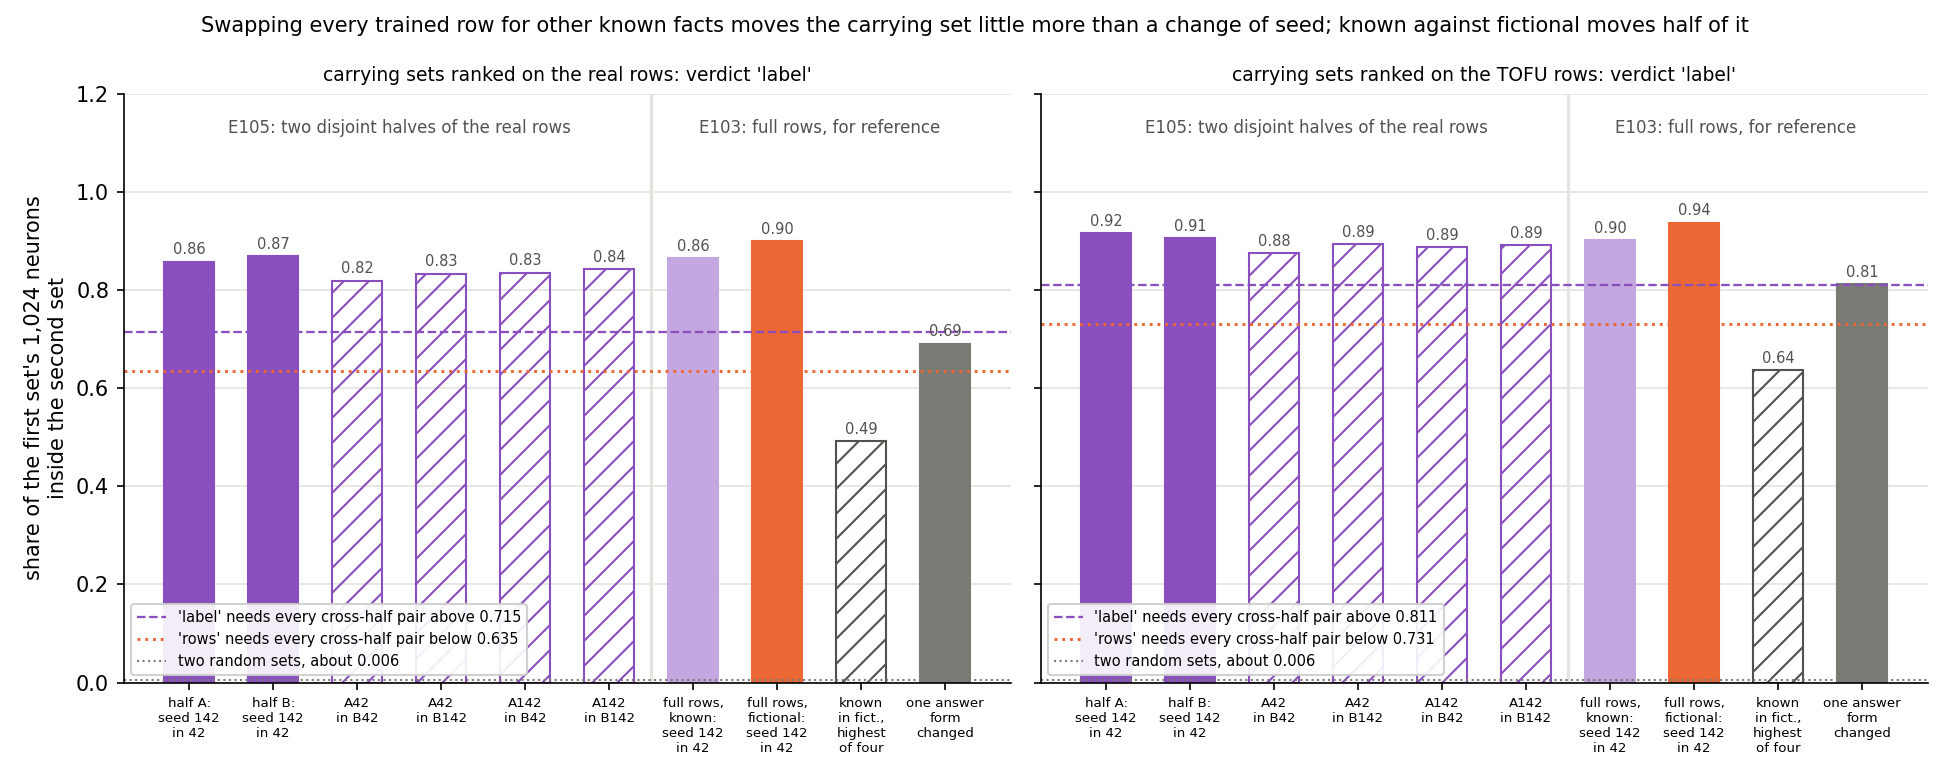

In [ ]:
display(Image(FIG / "overlap.png", width=950))


**Reading it.** No: it moves only a little more than a change of seed does, nowhere near as far as the change of arm.
The two solid purple bars in each panel are each half's two seeds; the four hatched purple bars are half A against
half B. On the real rows the seeds share 0.86 and 0.87 and the cross-half pairs 0.82 to 0.84, while E103's known and
fictional runs shared at most 0.49. On the fictional-author rows the cross-half pairs read 0.88 to 0.89, against a
cross-arm 0.64. Every pair is above the dashed "label" line, so the rule reads "label" on both.

The grey bar is the warning. Changing one of five answer forms on the same rows moved the set further than changing
every row did, to 0.69. The set follows the style of the training answers much more than which facts they hold.


### Does training half the rows twice as often move the set by itself?


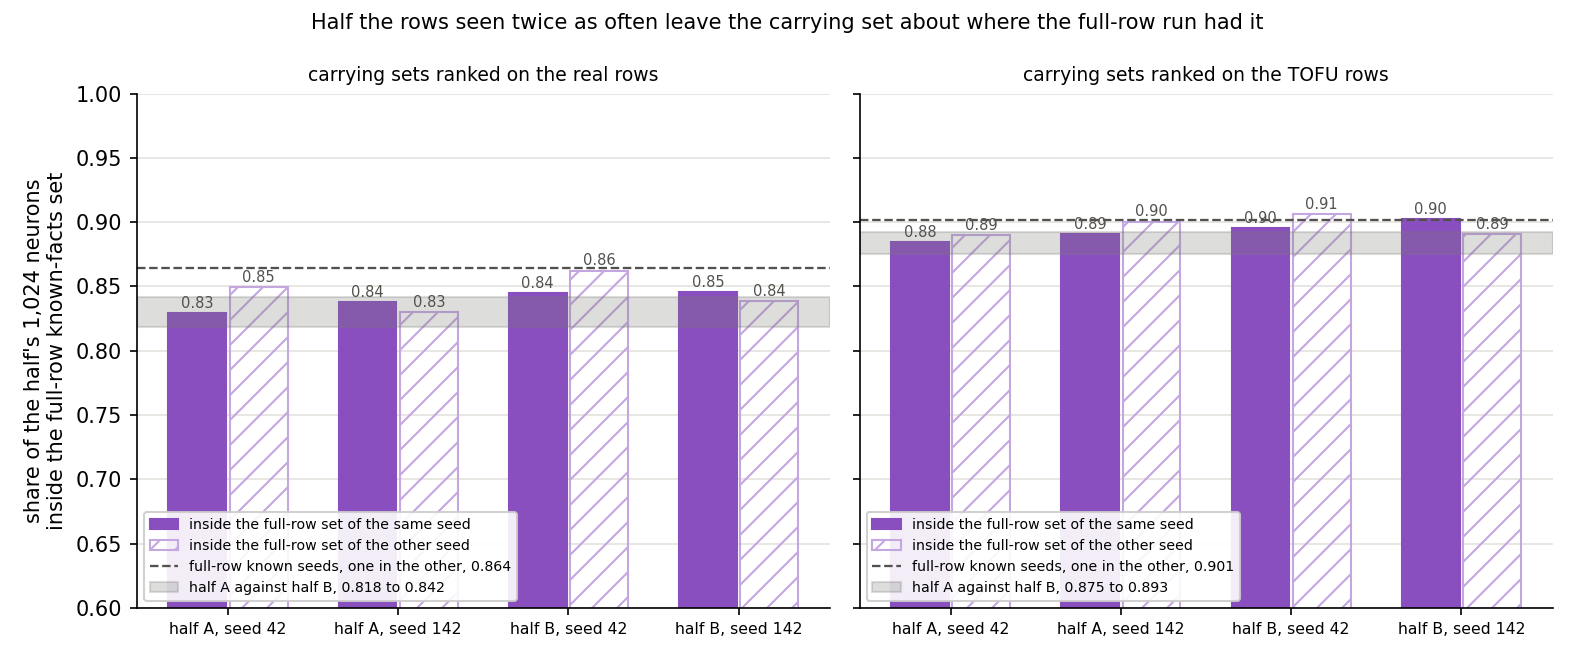

In [ ]:
display(Image(FIG / "bridge.png", width=850))


**Reading it.** Hardly. By step 32 a half has seen its rows about 0.95 times, the full-row run about 0.47 times. Each
bar is one half's set inside a full-row known set; the dashed line is the full-row seeds' overlap with each other. On
the real rows the halves sit at 0.83 to 0.85 inside the full-row set of their own seed, against the full seeds' 0.86.
On the fictional-author rows they sit at 0.88 to 0.90, against 0.90. Doubling the exposure leaves the set where the
full-row run had it, so E103's cross-arm level is a fair comparison for the halves.

### Is each half's update specific to its own rows?


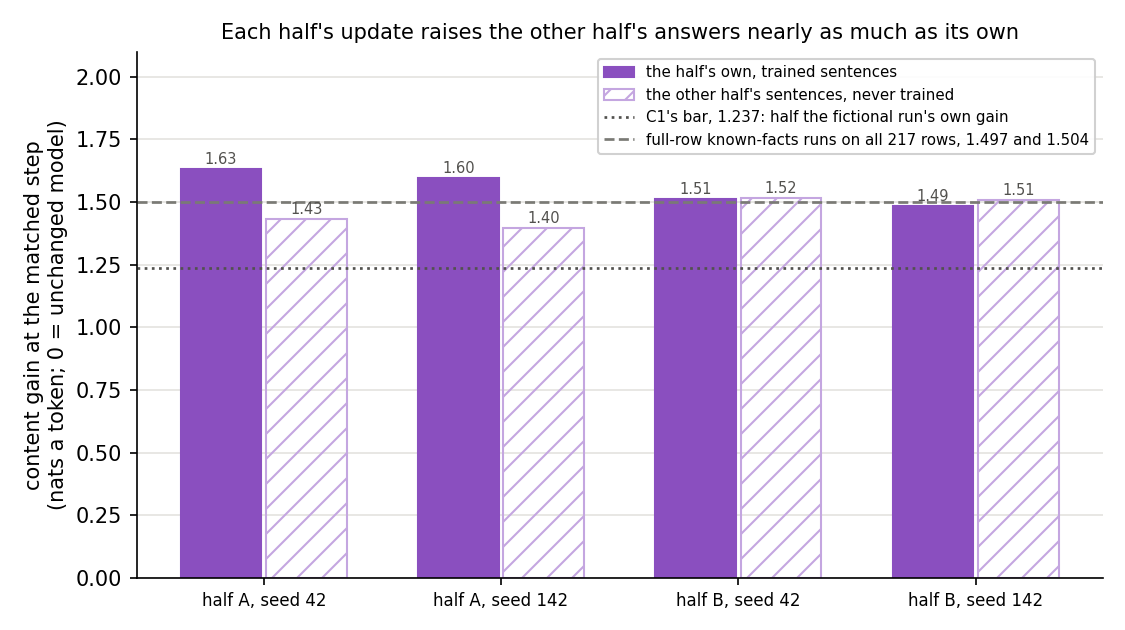

In [ ]:
display(Image(FIG / "gain.png", width=700))


**Reading it.** Mostly not, which is why the set barely moves. Solid bars are each run's gain on its own trained
sentences; hatched bars are its gain on the other half's sentences, which it never saw. Half A gains nine tenths as much
on half B's sentences as on its own. Half B gains as much on half A's as on its own. At this size each update has
mostly learned to answer this kind of question in a sentence, a skill that carries across the facts. So this null was
run where the particular rows were unlikely to matter.


## What we learned

- Which neurons carry the known-facts update does not depend on which known facts were trained: two disjoint halves
  give sets almost as alike as two seeds.
- So E103's separation is robust to the rows and the seed. It is still not a reading of known against new. The two
  arms also differ in topic and kind of entity, real famous people against invented authors, and in answer style, who
  wrote the answers and how. Answer style is the likeliest cause, since one changed answer form moved the set more than
  all the rows did.
- At the template's size each update is mostly a shared skill, not its facts. A change of style or topic could be all
  E103's neurons saw.

## How compelling is the evidence

- The null is clear: every cross-half pair clears the "label" line by at least 65 neurons of 1,024.
- The independent check re-derived every overlap and verdict exactly. Nothing in the measurement forces agreement: a
  random weight change shares about a quarter of every set, equally for both arms. With the neurons shared with both
  fictional seeds removed, the known-only remainders still agree across halves at 0.72 and 0.75. The agreement is flat
  from the top 32 neurons to the top 1,024.
- Two seeds per half and one random split. One matched size, inside warm-up.
- The null holds topic and answer style fixed along with the label, so it cannot separate them.
- Overlap misses rank changes inside a set, neurons just past the cut, and anything inside a neuron.

## Surprises

- **Both filed leans were wrong in direction.** The leans were "rows" on the real rows and "no call" on the
  fictional-author rows; both read "label", with cross-half overlaps far above the leans' ranges. Changing every row
  moved the set less than changing one answer form had.
- Half B gains as much on half A's sentences as on its own; the filed expectation had it below.

## What next

1. **A control that changes the label while holding topic and answer style.** For example, real facts of one kind,
   answered in sentences by one writer, split by whether the unchanged model already gets them right. If such a pair
   separates as far as E103's arms, set identity reads the label; if it shares as much as two halves do here, it read
   style or topic. A new plan.
2. **Carry set identity forward, labelled** as a reading of real-world against fictional-author training, robust to
   rows and seed, with answer style and topic named as live causes.
3. **A larger matched size**, where each update has learned more of its own rows.

## Scorecard

| claim | rule | read | verdict |
|---|---|---|---|
| controls: stored neuron read, reference level, first batches, early checks, matched step | stop rules | all exact or in band; step 32 ×4 | hold |
| own-half gain at the matched step | at least 1.2365 | 1.485 to 1.632 | holds ×4 |
| real rows: label, rows or no call | filed rule | seeds 0.857 / 0.869, cross 0.818 to 0.842, cross-arm 0.492 | **label**, lean was rows |
| fictional-author rows: the same | filed rule | seeds 0.916 / 0.905, cross 0.875 to 0.893, cross-arm 0.637 | **label**, lean was no call |
| cross-half overlaps, expected | real 0.50 to 0.62, TOFU 0.70 to 0.80 | 0.818 to 0.842; 0.875 to 0.893 | missed, above |
| other half's gain, expected | 0.8 to 1.6, below own | half A below own; half B equal | half A only |

## Not run

- A pair that changes the label while holding topic and answer style.
- A known-facts arm from a different topic in the same answer style.
- A fine-tune on a third dataset in the same format, read on these probes.
- A full-row known run at the halves' exposure; the bridge stands in.
- A same-label rows split for the fictional arm; more seeds; a different split.
- A larger matched size; VPD reads of the half states.

*Provenance: job 53480, one L40 on the cluster's `debug` QoS, 556 s, $0. Results `experiments/rows_null/results/`;
figures from `experiments/rows_null/plot.py`.*
